In [2]:
pip install contextily

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
    --------------------------------------- 0.5/31.5 MB 3.0 MB/s eta 0:00:11
   - -------------------------------------- 1.6/31.5 MB 3.8 MB/s eta 0:00:08
   -- ------------------------------------- 2.1/31.5 MB 3.6 MB/s eta 0:00:09
   -- ------------------------------------- 2.4/31.5 MB 3.4 MB/s eta 0:00:09
   -- ------------------------------------- 2.4/31.5 MB 3.4 MB/s eta 0:00:09
   --- ------------------------------------ 3.1/31.5 MB 2.4 MB/s eta 0:00:12
   ---- ----------------------------------- 3.9/31.5 MB 2.6 MB/s eta 0:00:11
   ----- ---------------------------------- 4.5/31.5 MB 2.7 MB/s eta 0:00:11
   ------ --------------------------------- 5.2/31.5 MB 2.8 MB/s eta 0:00:10
   ------- -------------------------------- 5.8/31.5 MB 2.7 MB/s eta 0:00:10
   -------- ------------------------------- 6.6/31.5 MB 2.8 MB/s eta 0:00:09
   --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Libraries are Imported

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import contextily as cx
import pandas as pd
import geopandas as gpd

Data Loaded and coverted so that all follow EPSG:27700 (Eastings and Northings)

In [15]:
supplyDf = pd.read_excel("regulated.xlsx")
supplies = gpd.GeoDataFrame(supplyDf, 
                            geometry = gpd.points_from_xy(supplyDf.Eastings, supplyDf.Northings),
                            crs = "EPSG:27700")
borders = gpd.read_file("scottishBorders.geojson")
bordersEN = borders.to_crs(epsg = 27700)

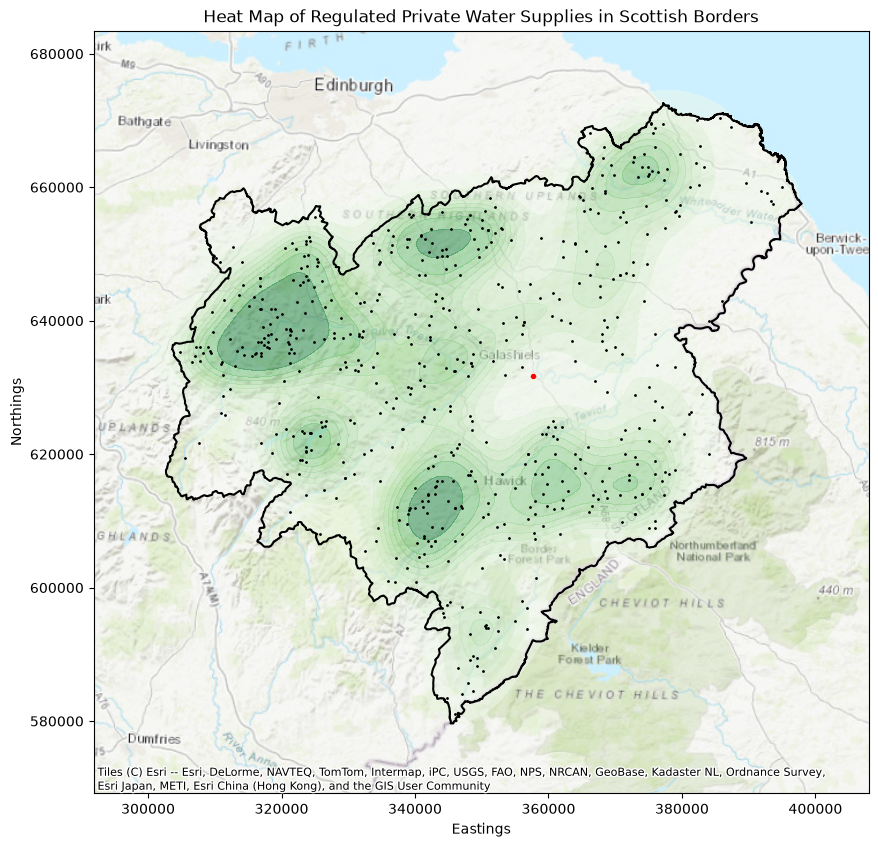

In [48]:
figure, axis = plt.subplots(figsize = (10, 10))
plt.xlabel("Eastings")
plt.ylabel("Northings")
plt.title("Heat Map of Regulated Private Water Supplies in Scottish Borders")
sns.kdeplot(
    x = supplies.geometry.x,
    y = supplies.geometry.y,
    fill = True,
    cmap = "Greens",
    alpha = 0.5,
    levels = 10,
    bw_adjust = 0.6,
    ax = axis)
bordersEN.boundary.plot(ax = axis, color = "black")
supplies.plot(ax = axis, color = "black", markersize = 1)
cx.add_basemap(axis, crs=supplies.crs, source=cx.providers.Esri.WorldTopoMap)
axis.scatter(357638 , 631750, marker = "H", color = "Red", s = 10)